In [1]:
# import subprocess

# subprocess.run(["pip", "install", "-U", "bitsandbytes>=0.46.1", "-q"], check=True)
# subprocess.run(["pip", "install", "transformers==4.44.2", "-q"], check=True)  # ✅ pinned
# subprocess.run(["pip", "install", "-U", "accelerate", "-q"], check=True)

# print("✅ Done — RESTART KERNEL now, then run Cell 2")

In [2]:
# ================================================================
# GLOBAL SEED FIX — run this FIRST before any import
# Fixes all sources of randomness
# ================================================================
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

# ── 1. Python built-in random ────────────────────────────────────
random.seed(SEED)

# ── 2. NumPy ─────────────────────────────────────────────────────
np.random.seed(SEED)

# ── 3. TensorFlow / Keras ────────────────────────────────────────
tf.random.set_seed(SEED)

# ── 4. OS environment (covers some C-level randomness) ───────────
os.environ['PYTHONHASHSEED'] = str(SEED)

# ── 5. CUDA GPU deterministic operations ─────────────────────────
os.environ['TF_DETERMINISTIC_OPS']        = '1'
os.environ['TF_CUDNN_DETERMINISTIC']      = '1'
os.environ['TF_DISABLE_SEGMENT_REDUCTION_OP_DETERMINISM_EXCEPTIONS'] = '1'

# ── 6. Disable GPU memory growth (stabilizes behaviour) ──────────
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

print(f"✅ All seeds fixed to {SEED}")
print(f"   Python   : {SEED}")
print(f"   NumPy    : {SEED}")
print(f"   TF/Keras : {SEED}")
print(f"   GPU Deterministic : ON")

✅ All seeds fixed to 42
   Python   : 42
   NumPy    : 42
   TF/Keras : 42
   GPU Deterministic : ON


In [3]:
# import gc
# import torch

# # ── Kill any leftover models from previous cells
# for obj_name in ['model_llama', 'tokenizer_llama', 'model_gpt2', 
#                   'model_falcon', 'tokenizer_falcon']:
#     if obj_name in dir():
#         del obj_name

# gc.collect()
# torch.cuda.empty_cache()
# # torch.cuda.synchronize()

# # ── Check available VRAM before loading
# total  = torch.cuda.get_device_properties(0).total_memory / 1e9
# reserved = torch.cuda.memory_reserved(0) / 1e9
# free   = total - reserved
# print(f"GPU Total  : {total:.1f} GB")
# print(f"GPU Reserved: {reserved:.1f} GB")
# print(f"GPU Free   : {free:.1f} GB")
# # You need at least 8GB free before loading LLaMA

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Text cleaning
import re
import string
# import emoji
import nltk
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.corpus import stopwords

# Data preprocessing
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
# from imblearn.over_sampling import RandomOverSampler
# from langdetect import detect, LangDetectException
# import contractions
from nltk.tokenize import word_tokenize

# Naive Bayes
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight
# PyTorch LSTM
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import torch.optim as optim
# from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler

# Tokenization for LSTM
from collections import Counter
from gensim.models import Word2Vec

import numpy as np
import tensorflow as tf

# Fix for TF 2.x — import keras directly
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from tensorflow.keras import backend as K

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score,
    roc_curve, confusion_matrix,
)
import matplotlib.pyplot as plt
import gc

print("TF version :", tf.__version__)
print("Keras version:", keras.__version__)
print("GPU        :", tf.config.list_physical_devices('GPU'))

tf.random.set_seed(42)
np.random.seed(42)
print("✅ Imports done")

# Transformers library for BERT
import transformers
# from transformers import BertModel
# from transformers import BertTokenizer
# from transformers import  get_linear_schedule_with_warmup
# from transformers import BertModel, BertTokenizer
# from torch.optim import AdamW
# from transformers import get_linear_schedule_with_warmup
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from xgboost import XGBClassifier
import tensorflow as tf
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.layers import SimpleRNN, MaxPooling1D
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt
from sklearn.metrics import matthews_corrcoef
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn import metrics
from keras.callbacks import EarlyStopping
import time

TF version : 2.21.0
Keras version: 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
✅ Imports done


In [5]:
# del model
# del tokenizer
# gc.collect()
# torch.cuda.empty_cache()

In [6]:
print("=" * 55)
print("STEP 1: LOADING DATASET")
print("=" * 55)

data = []
with open('/kaggle/input/datasets/almahmudsiam/conference-llm/Dataset for Detection of Cyber-Trolls.json', 'r') as f:
    for line in f:
        line = line.strip()
        if line:
            data.append(json.loads(line))

df = pd.DataFrame({
    'text' : [d['content'] for d in data],
    'label': [int(d['annotation']['label'][0]) for d in data]
})

print(f"Total samples : {len(df)}")
print(f"Columns       : {list(df.columns)}")
print(f"\nLabel distribution:")
print(df['label'].value_counts())
print(f"\nLabel percentage:")
print(df['label'].value_counts(normalize=True).mul(100).round(2))

STEP 1: LOADING DATASET
Total samples : 20001
Columns       : ['text', 'label']

Label distribution:
label
0    12179
1     7822
Name: count, dtype: int64

Label percentage:
label
0    60.89
1    39.11
Name: proportion, dtype: float64


In [7]:
df

,text,label
0,Get fucking real dude.,1
1,She is as dirty as they come and that crook ...,1
2,why did you fuck it up. I could do it all day...,1
3,Dude they dont finish enclosing the fucking s...,1
4,WTF are you talking about Men? No men thats n...,1
...,...,...
19996,I dont. But what is complaining about it goi...,0
19997,Bahah yeah i&;m totally just gonna&; get pis...,0
19998,hahahahaha >:) im evil mwahahahahahahahahaha,0
19999,What&;s something unique about Ohio? :),0


In [8]:
print("\n" + "=" * 55)
print("STEP 2: DATA EXPLORATION")
print("=" * 55)

df['text_length']  = df['text'].apply(len)
df['word_count']   = df['text'].apply(lambda x: len(x.split()))

print(f"\nText length stats:")
print(df['text_length'].describe().round(2))

print(f"\nWord count stats:")
print(df['word_count'].describe().round(2))

# Length by class
print(f"\nAvg word count by class:")
print(df.groupby('label')['word_count'].mean().round(2))


STEP 2: DATA EXPLORATION

Text length stats:
count    20001.00
mean        67.71
std         47.22
min          1.00
25%         32.00
50%         60.00
75%        101.00
max       1738.00
Name: text_length, dtype: float64

Word count stats:
count    20001.00
mean        12.97
std          9.20
min          1.00
25%          6.00
50%         12.00
75%         19.00
max        343.00
Name: word_count, dtype: float64

Avg word count by class:
label
0    12.54
1    13.65
Name: word_count, dtype: float64


In [9]:
print("\n" + "=" * 55)
print("STEP 3: DATA QUALITY CHECK")
print("=" * 55)

# Duplicates
dupes = df.duplicated(subset='text').sum()
print(f"Duplicate texts : {dupes}")


# Null/empty
nulls = df['text'].isna().sum()
print(f"Null texts      : {nulls}")

# Sample from each class
print(f"\nSample Troll (label=1):")
for t in df[df['label']==1]['text'].head(3).values:
    print(f"  → {t[:80]}")

print(f"\nSample Non-Troll (label=0):")
for t in df[df['label']==0]['text'].head(3).values:
    print(f"  → {t[:80]}")


STEP 3: DATA QUALITY CHECK
Duplicate texts : 5361
Null texts      : 0

Sample Troll (label=1):
  →  Get fucking real dude.
  →  She is as dirty as they come  and that crook Rengel  the Dems are so fucking co
  →  why did you fuck it up. I could do it all day too. Let's do it when you have an

Sample Non-Troll (label=0):
  → yeah I got 2 backups for all that. I just hate when that happen. I been struggli
  → I hate using my BB  but love my iPhone. Haven't tried the new BB. My BB is provi
  → wow lol sounds like a lot of piss then hehehe


In [10]:
print("\n" + "=" * 55)
print("STEP 4: PREPROCESSING")
print("=" * 55)

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)
nltk.download('punkt',     quiet=True)

from nltk.corpus import stopwords
from nltk.stem   import WordNetLemmatizer

lemmatizer   = WordNetLemmatizer()
stop_words   = set(stopwords.words('english'))

# Keep negations — important for troll detection!
negations = {
    'no','not','nor','neither','never','nobody',
    'nothing','nowhere','nor','cannot','cant',
    "can't","won't","wouldn't","shouldn't",
    "couldn't","didn't","doesn't","don't","isn't",
    "aren't","wasn't","weren't","hadn't","hasn't",
    "haven't","needn't","mustn't"
}
# Remove negations from stopwords
all_stopwords = stop_words - negations

def preprocess_troll(text):
    """
    Preprocessing for Cyber-Troll detection.
    Preserves:
    - ALL CAPS words (aggression signal)
    - Negations (semantic importance)
    - Exclamation marks count (aggression)
    """
    if not isinstance(text, str):
        return ""

    text = str(text)

    # Step 1: Remove URLs
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' ', text)

    # Step 2: Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Step 3: Remove emails
    text = re.sub(r'\S+@\S+\.\S+', ' ', text)

    # Step 4: Remove @mentions
    text = re.sub(r'@\w+', ' ', text)

    # Step 5: Remove hashtags
    text = re.sub(r'#\w+', ' ', text)

    # Step 6: Expand contractions
    contractions = {
        "won't":"will not", "can't":"cannot",
        "n't":" not", "'re":" are", "'s":" is",
        "'d":" would", "'ll":" will",
        "'t":" not", "'ve":" have", "'m":" am"
    }
    for k, v in contractions.items():
        text = text.replace(k, v)

    # Step 7: Tokenize
    tokens = text.split()

    # Step 8: Preserve CAPS, lowercase others
    processed = []
    for token in tokens:
        if token.isupper() and len(token) > 1:
            processed.append(token)        # Keep HATE, KILL, WTF
        else:
            processed.append(token.lower())

    # Step 9: Remove punctuation (after CAPS preservation)
    processed = [
        t.translate(str.maketrans('', '', string.punctuation))
        for t in processed
    ]

    # Step 10: Remove empty tokens
    processed = [t for t in processed if t.strip()]

    # Step 11: Remove stopwords (keep negations)
    processed = [
        t for t in processed
        if t not in all_stopwords or t in negations
    ]

    # Step 12: Keep words with length >= 2
    processed = [t for t in processed if len(t) >= 2]

    # Step 13: Keep alphabetic only
    processed = [t for t in processed if t.isalpha()]

    # Step 14: Lemmatization
    processed = [lemmatizer.lemmatize(t) for t in processed]

    return ' '.join(processed)


STEP 4: PREPROCESSING


In [11]:
# print("Applying preprocessing...")
df['text_clean'] = df['text'].apply(preprocess_troll)

# Verify
# print(f"\nSample before/after preprocessing:")
# for i in [0, 1, 2]:
#     print(f"\nOriginal : {df['text'].iloc[i][:80]}")
#     print(f"Cleaned  : {df['text_clean'].iloc[i][:80]}")

In [12]:
print("\n" + "=" * 55)
print("STEP 5: POST-PROCESSING CHECK")
print("=" * 55)

df['clean_length'] = df['text_clean'].apply(len)
df['clean_words']  = df['text_clean'].apply(
    lambda x: len(x.split()) if x.strip() else 0)

# Check empty after cleaning
empty_after = (df['text_clean'].str.strip() == '').sum()
print(f"Empty after cleaning : {empty_after}")

# Remove empty rows
df_clean = df[df['text_clean'].str.strip() != ''].copy()
print(f"Remaining samples    : {len(df_clean)}")
print(f"Removed samples      : {len(df) - len(df_clean)}")

print(f"\nClean word count stats:")
print(df_clean['clean_words'].describe().round(2))

print(f"\nFinal label distribution:")
print(df_clean['label'].value_counts())
print(df_clean['label'].value_counts(
    normalize=True).mul(100).round(2))


STEP 5: POST-PROCESSING CHECK
Empty after cleaning : 167
Remaining samples    : 19834
Removed samples      : 167

Clean word count stats:
count    19834.00
mean         7.13
std          4.82
min          1.00
25%          3.00
50%          6.00
75%         10.00
max        129.00
Name: clean_words, dtype: float64

Final label distribution:
label
0    12038
1     7796
Name: count, dtype: int64
label
0    60.69
1    39.31
Name: proportion, dtype: float64


In [13]:
print("\n" + "=" * 55)
print("STEP 6: FINAL DATASET READY")
print("=" * 55)

# Keep only needed columns
df_final = df_clean[['text', 'text_clean', 'label']].reset_index(drop=True)

# print(f"Final dataset shape : {df_final.shape}")
# print(f"\nReady for:")
# print(f"  X = df_final['text_clean']")
# print(f"  y = df_final['label']")
# print(f"\nSample final data:")
# print(df_final.head(3).to_string())


STEP 6: FINAL DATASET READY


In [14]:
df_final

,text,text_clean,label
0,Get fucking real dude.,get fucking real dude,1
1,She is as dirty as they come and that crook ...,dirty come crook rengel dems fucking corrupt j...,1
2,why did you fuck it up. I could do it all day...,fuck could day let hour ping later sched writi...,1
3,Dude they dont finish enclosing the fucking s...,dude dont finish enclosing fucking shower hate...,1
4,WTF are you talking about Men? No men thats n...,WTF talking men no men thats not menage gay,1
...,...,...,...
19829,I dont. But what is complaining about it goi...,dont complaining going,0
19830,Bahah yeah i&;m totally just gonna&; get pis...,bahah yeah im totally gonna get pissed talking...,0
19831,hahahahaha >:) im evil mwahahahahahahahahaha,hahahahaha im evil mwahahahahahahahahaha,0
19832,What&;s something unique about Ohio? :),whats something unique ohio,0


In [15]:
label_map = (
    df.groupby('text_clean')['label']
    .agg(lambda x: 1 if x.value_counts().get(1,0) >= x.value_counts().get(0,0) else 0)
)

# df_final = df.copy()
df_final['label'] = df_final['text_clean'].map(label_map)

print("Final shape:", df_final.shape)

Final shape: (19834, 3)


In [16]:

from sklearn.model_selection import train_test_split

X = df_final['text_clean']
y = df_final['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


In [17]:
def generate_model_report(y_actual, y_predicted):
    y_actual = np.array(y_actual).astype(int)
    y_predicted = np.array(y_predicted).astype(int)
    print("Accuracy = " , accuracy_score(y_actual, y_predicted))
    print("Precision = " ,precision_score(y_actual, y_predicted))
    print("Recall = " ,recall_score(y_actual, y_predicted))
    print("F1 Score = " ,f1_score(y_actual, y_predicted))
    print("MCC       =", matthews_corrcoef(y_actual, y_predicted))
    pass


def generate_auc_roc_curve(clf, X_test):
    y_pred_proba = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(Y_test,  y_pred_proba)
    auc = roc_auc_score(Y_test, y_pred_proba)
    plt.plot(fpr,tpr,label="AUC ROC Curve with Area Under the curve ="+str(auc))
    plt.legend(loc=4)
    plt.show()
    pass

# TF-IDF

In [18]:
max_words = 10000
max_len   = 100

# ----------------------------
# 2️⃣ TF-IDF vectorization
# ----------------------------
tfidf = TfidfVectorizer(max_features=25000)
X_tfidf_train = tfidf.fit_transform(X_train)
X_tfidf_test = tfidf.transform(X_test)
feature_names = tfidf.get_feature_names_out()

# XGB

In [21]:
# ans = 0
# for i in range (100,300):
xb_tfidf = XGBClassifier(
    colsample_bytree=0.73,
    gamma=0.09,
    learning_rate=0.15,
    max_depth=93,
    min_child_weight=1,
    n_estimators=165,
    reg_alpha=0.2923,
    reg_lambda=4.5861,
    subsample=0.810,
    random_state=42

)

xb_tfidf.fit(X_tfidf_train, y_train)
x_train_prediction = xb_tfidf.predict(X_tfidf_train)
training_data_accuracy = accuracy_score(x_train_prediction , y_train)
print('Accuracy score on Training data XGBoost:' ,training_data_accuracy)


x_test_prediction = xb_tfidf.predict(X_tfidf_test)
test_data_accuracy=accuracy_score(x_test_prediction,y_test)

# if test_data_accuracy >= ans:
#     print("======================================>")
#     print('i',i)
#     ans = test_data_accuracy
test_data_accuracy=accuracy_score(x_test_prediction,y_test)
print('Accuracy score on Test data XGBoost:' ,test_data_accuracy)
    
generate_model_report(y_test, x_test_prediction)
cf_matrix=confusion_matrix(x_test_prediction,y_test)

Accuracy score on Training data XGBoost: 0.9840549568286381
Accuracy score on Test data XGBoost: 0.8888328711872951
Accuracy =  0.8888328711872951
Precision =  0.8194600674915635
Recall =  0.9239061509194674
F1 Score =  0.8685543964232488
MCC       = 0.7770183366991805


# ET

In [22]:
et_tfidf = ExtraTreesClassifier(bootstrap= False, 
                          criterion='gini', 
                          max_depth= None, 
                          max_features= 'log2', 
                          min_samples_leaf= 1, 
                          min_samples_split=2, 
                          n_estimators=9,
                          random_state=410)

et_tfidf.fit(X_tfidf_train, y_train)
x_train_prediction = et_tfidf.predict(X_tfidf_train)
training_data_accuracy = accuracy_score(x_train_prediction , y_train)
print('Accuracy score on Training data ExtraTree:' ,training_data_accuracy)

x_test_prediction = et_tfidf.predict(X_tfidf_test)
test_data_accuracy=accuracy_score(x_test_prediction,y_test)
print('Accuracy score on Test data ExtraTree:' ,test_data_accuracy)

generate_model_report(y_test, x_test_prediction)
cf_matrix=confusion_matrix(x_test_prediction,y_test)


Accuracy score on Training data ExtraTree: 0.9997479044557888
Accuracy score on Test data ExtraTree: 0.9518527854802118
Accuracy =  0.9518527854802118
Precision =  0.9246323529411765
Recall =  0.9568801521876982
F1 Score =  0.9404799002804612
MCC       = 0.9004493866495321


# RF

In [23]:
ans = 0
# for i in range (51,200):

rf_tfidf = RandomForestClassifier(
    max_depth=None,
    max_features='sqrt',  # Fix here
    min_samples_leaf=1, # 1
    min_samples_split=2,
    n_estimators=64, #40
    random_state=42
)

rf_tfidf.fit(X_tfidf_train, y_train)
x_train_prediction = rf_tfidf.predict(X_tfidf_train)
training_data_accuracy = accuracy_score(x_train_prediction , y_train)
print('Accuracy score on Training data RandomForest:' ,training_data_accuracy)
    
    
x_test_prediction = rf_tfidf.predict(X_tfidf_test)
test_data_accuracy=accuracy_score(x_test_prediction,y_test)
# if test_data_accuracy > ans:
    # ans = test_data_accuracy
    # print("===========================>",  i)
print('Accuracy score on Test data RandomForest:' ,test_data_accuracy)
    
generate_model_report(y_test, x_test_prediction)
cf_matrix=confusion_matrix(x_test_prediction,y_test)

Accuracy score on Training data RandomForest: 0.9997479044557888
Accuracy score on Test data RandomForest: 0.9319384925636501
Accuracy =  0.9319384925636501
Precision =  0.877527440785673
Recall =  0.9632213062777425
F1 Score =  0.9183796856106409
MCC       = 0.8629771645738381


# Word2Vec

In [24]:

from gensim.models import Word2Vec
import numpy as np

# ----------------------------
# Word2Vec Configuration
# ----------------------------
vector_size = 300
window = 5
min_count = 1

# Tokenization
train_tokens = [text.split() for text in X_train]
test_tokens = [text.split() for text in X_test]

# Train Word2Vec on training data only
w2v = Word2Vec(
    sentences=train_tokens,
    vector_size=vector_size,
    window=window,
    min_count=min_count,
    workers=1,
    sg=1,
    epochs=20,
    seed=42
)

# Convert each text into a 300-dimensional vector
def get_w2v_vector(tokens):
    vectors = [
        w2v.wv[word]
        for word in tokens
        if word in w2v.wv
    ]

    if len(vectors) == 0:
        return np.zeros(vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0)

# Word2Vec feature extraction
X_w2v_train = np.array([
    get_w2v_vector(tokens) for tokens in train_tokens
])

X_w2v_test = np.array([
    get_w2v_vector(tokens) for tokens in test_tokens
])

print("Training shape:", X_w2v_train.shape)
print("Testing shape :", X_w2v_test.shape)


Training shape: (15867, 300)
Testing shape : (3967, 300)


# rf

In [25]:
ans = 0
# for i in range (1,10):

rf_w2v = RandomForestClassifier(
max_depth=None,
max_features='sqrt',  # Fix here
min_samples_leaf=1, # 1
min_samples_split=2,  #2
n_estimators=56, #64
random_state=42
)

rf_w2v.fit(X_w2v_train, y_train)
x_train_prediction = rf_w2v.predict(X_w2v_train)
training_data_accuracy = accuracy_score(x_train_prediction , y_train)
print('Accuracy score on Training data RandomForest:' ,training_data_accuracy)


x_test_prediction = rf_w2v.predict(X_w2v_test)
test_data_accuracy=accuracy_score(x_test_prediction,y_test)
# if test_data_accuracy > ans:
#     ans = test_data_accuracy
#     print("===========================>",  i)
print('Accuracy score on Test data RandomForest:' ,test_data_accuracy)

generate_model_report(y_test, x_test_prediction)
cf_matrix=confusion_matrix(x_test_prediction,y_test)

Accuracy score on Training data RandomForest: 0.9998739522278943
Accuracy score on Test data RandomForest: 0.9558860599949585
Accuracy =  0.9558860599949585
Precision =  0.9321824907521579
Recall =  0.9587824984147115
F1 Score =  0.9452954048140044
MCC       = 0.9086012047431721


# ET

In [26]:
ans = 0 

# for i in [100, 200, 300, 500]:
et_w2v = ExtraTreesClassifier(bootstrap= False, 
                  criterion='entropy', 
                  max_depth= None, 
                  max_features= 'sqrt', 
                  min_samples_leaf= 1,  #1
                  min_samples_split=2, # 2 
                  n_estimators=200,  #200
                  random_state=42)

et_w2v.fit(X_w2v_train, y_train)
x_train_prediction = et_w2v.predict(X_w2v_train)
training_data_accuracy = accuracy_score(x_train_prediction , y_train)
print('Accuracy score on Training data ExtraTree:' ,training_data_accuracy)

x_test_prediction = et_w2v.predict(X_w2v_test)
test_data_accuracy=accuracy_score(x_test_prediction,y_test)
# if (test_data_accuracy > ans):
#     ans = test_data_accuracy
#     print("="*22)
#     print("i :",i)
print('Accuracy score on Test data ExtraTree:' ,test_data_accuracy)

generate_model_report(y_test, x_test_prediction)
cf_matrix=confusion_matrix(x_test_prediction,y_test)


Accuracy score on Training data ExtraTree: 0.9999369761139472
Accuracy score on Test data ExtraTree: 0.9687421225107133
Accuracy =  0.9687421225107133
Precision =  0.968407479045777
Recall =  0.9524413443246671
F1 Score =  0.9603580562659847
MCC       = 0.9346479061700594


# XB

In [27]:
ans = 0
# for i in [0.6, 0.73, 0.8]:
xb_w2v = XGBClassifier(
colsample_bytree=0.8,   #0.8
gamma=0.09,
learning_rate=0.15,
max_depth=7,  #7
min_child_weight=1,
n_estimators=160,  #165
reg_alpha=0.2,  #0.2
reg_lambda=4,   #4.5861,
subsample=0.7,   # 0.7,
random_state=42,
n_jobs=-1,
eval_metric='logloss'
)

xb_w2v.fit(X_w2v_train, y_train)
x_train_prediction = xb_w2v.predict(X_w2v_train)
training_data_accuracy = accuracy_score(x_train_prediction , y_train)
print('Accuracy score on Training data XGBoost:' ,training_data_accuracy)


x_test_prediction = xb_w2v.predict(X_w2v_test)
test_data_accuracy=accuracy_score(x_test_prediction,y_test)

# if test_data_accuracy >= ans:
#     print("======================================>")
#     print('i',i)
#     ans = test_data_accuracy
test_data_accuracy=accuracy_score(x_test_prediction,y_test)
print('Accuracy score on Test data XGBoost:' ,test_data_accuracy)
    
generate_model_report(y_test, x_test_prediction)
cf_matrix=confusion_matrix(x_test_prediction,y_test)

Accuracy score on Training data XGBoost: 0.9989916178231549
Accuracy score on Test data XGBoost: 0.9410133602218301
Accuracy =  0.9410133602218301
Precision =  0.8956982911019447
Recall =  0.963855421686747
F1 Score =  0.9285277947464875
MCC       = 0.8801401004931578


# Falcon-7B

In [28]:

# ============================================================
# CELL 1 — IMPORTS AND DEVICE CONFIGURATION
# Original Falcon-7B Experiment
# ============================================================

import os
import gc
import time
import torch
import numpy as np

from transformers import AutoTokenizer, AutoModelForCausalLM

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch version:", torch.__version__)

assert torch.cuda.is_available(), "Please enable Kaggle GPU."


Device: cuda
PyTorch version: 2.11.0+cu130


In [29]:

# ============================================================
# CELL 2 — LOAD FALCON-7B MODEL
# Model: tiiuae/falcon-7b
# Precision: FP16
# No fine-tuning / No 4-bit quantization
# ============================================================

MODEL_NAME = "tiiuae/falcon-7b"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

tokenizer.pad_token = tokenizer.eos_token

# Explicit setting for last non-padding token selection
tokenizer.padding_side = "right"

model.config.pad_token_id = tokenizer.eos_token_id

print("Falcon-7B loaded successfully!")
print("Hidden size:", model.config.hidden_size)
print("Precision:", torch.float16)


config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/281 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/17.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

Falcon-7B loaded successfully!
Hidden size: 4544
Precision: torch.float16


In [30]:

# ============================================================
# CELL 3 — FALCON-7B FEATURE EXTRACTION
# Final hidden layer + Last non-padding token
# ============================================================

def extract_falcon_embeddings(
    texts,
    tokenizer,
    model,
    batch_size=2,
    max_len=128,
):

    all_embeddings = []
    total = len(texts)

    print(f"\nExtracting Falcon-7B embeddings")
    print(f"Samples: {total} | Batch: {batch_size} | MaxLen: {max_len}")

    for i in range(0, total, batch_size):

        batch = list(texts[i:i + batch_size])

        encoded = tokenizer(
            batch,
            padding="max_length",
            truncation=True,
            max_length=max_len,
            return_tensors="pt",
        )

        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)

        with torch.no_grad():
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                output_hidden_states=True,
            )

        # Final hidden layer
        last_hidden = outputs.hidden_states[-1]

        # Last non-padding token
        seq_idx = attention_mask.sum(dim=1) - 1
        seq_idx = seq_idx.to(last_hidden.device)

        batch_n = last_hidden.size(0)

        emb = last_hidden[
            torch.arange(batch_n, device=last_hidden.device),
            seq_idx
        ].cpu().float().numpy()

        all_embeddings.append(emb)

        if i % (batch_size * 20) == 0:
            print(f"  {min(i + batch_size, total)}/{total}")

    X = np.vstack(all_embeddings)

    print("Embedding shape:", X.shape)

    return X


In [31]:

# ============================================================
# CELL 4 — EXTRACT AND SAVE FALCON-7B EMBEDDINGS
# ============================================================

SAVE_DIR = "/kaggle/working/embeddings"
os.makedirs(SAVE_DIR, exist_ok=True)

TRAIN_PATH = f"{SAVE_DIR}/falcon7b_train.npy"
TEST_PATH = f"{SAVE_DIR}/falcon7b_test.npy"

# Prevent accidentally overwriting existing embeddings
if os.path.exists(TRAIN_PATH) or os.path.exists(TEST_PATH):
    raise FileExistsError(
        "Existing Falcon embedding files found. "
        "Verify them before running extraction again."
    )

start = time.time()

# ---------------------------
# Training embeddings
# ---------------------------

X_train_falcon = extract_falcon_embeddings(
    X_train.values,
    tokenizer,
    model,
    batch_size=2,
    max_len=128,
)

np.save(TRAIN_PATH, X_train_falcon)

print("Training embeddings saved:", TRAIN_PATH)

# ---------------------------
# Testing embeddings
# ---------------------------

X_test_falcon = extract_falcon_embeddings(
    X_test.values,
    tokenizer,
    model,
    batch_size=2,
    max_len=128,
)

np.save(TEST_PATH, X_test_falcon)

print("Testing embeddings saved:", TEST_PATH)

extract_time = time.time() - start

print("\n===== FALCON-7B EXTRACTION COMPLETED =====")

print("Training:", X_train_falcon.shape)
print("Testing :", X_test_falcon.shape)
print("Extraction time:", round(extract_time, 2), "seconds")



Extracting Falcon-7B embeddings
Samples: 15867 | Batch: 2 | MaxLen: 128
  2/15867
  42/15867
  82/15867
  122/15867
  162/15867
  202/15867
  242/15867
  282/15867
  322/15867
  362/15867
  402/15867
  442/15867
  482/15867
  522/15867
  562/15867
  602/15867
  642/15867
  682/15867
  722/15867
  762/15867
  802/15867
  842/15867
  882/15867
  922/15867
  962/15867
  1002/15867
  1042/15867
  1082/15867
  1122/15867
  1162/15867
  1202/15867
  1242/15867
  1282/15867
  1322/15867
  1362/15867
  1402/15867
  1442/15867
  1482/15867
  1522/15867
  1562/15867
  1602/15867
  1642/15867
  1682/15867
  1722/15867
  1762/15867
  1802/15867
  1842/15867
  1882/15867
  1922/15867
  1962/15867
  2002/15867
  2042/15867
  2082/15867
  2122/15867
  2162/15867
  2202/15867
  2242/15867
  2282/15867
  2322/15867
  2362/15867
  2402/15867
  2442/15867
  2482/15867
  2522/15867
  2562/15867
  2602/15867
  2642/15867
  2682/15867
  2722/15867
  2762/15867
  2802/15867
  2842/15867
  2882/15867
  2922/

In [32]:

# ============================================================
# CELL 5 — VERIFY EMBEDDINGS AND CLEAN GPU MEMORY
# ============================================================

print("Train shape:", X_train_falcon.shape)
print("Test shape :", X_test_falcon.shape)

assert X_train_falcon.shape == (len(X_train), 4544)
assert X_test_falcon.shape == (len(X_test), 4544)

assert np.isfinite(X_train_falcon).all()
assert np.isfinite(X_test_falcon).all()

print("\nSaved files:")

for path in [TRAIN_PATH, TEST_PATH]:
    print(
        os.path.basename(path),
        round(os.path.getsize(path) / (1024 ** 2), 2),
        "MiB"
    )

del model, tokenizer
gc.collect()
torch.cuda.empty_cache()

print("\nFalcon-7B model freed from memory.")
print("Embeddings verified successfully.")


Train shape: (15867, 4544)
Test shape : (3967, 4544)

Saved files:
falcon7b_train.npy 275.04 MiB
falcon7b_test.npy 68.76 MiB

Falcon-7B model freed from memory.
Embeddings verified successfully.


In [33]:

# ============================================================
# CELL 6 — PREPARE FALCON DATASET FOR KAGGLE
# ============================================================

import os
import shutil
import numpy as np

SOURCE_DIR = "/kaggle/working/embeddings"
FALCON_DIR = "/kaggle/working/falcon"

os.makedirs(FALCON_DIR, exist_ok=True)

files = [
    "falcon7b_train.npy",
    "falcon7b_test.npy"
]

for filename in files:
    source = os.path.join(SOURCE_DIR, filename)
    destination = os.path.join(FALCON_DIR, filename)

    if not os.path.isfile(source):
        raise FileNotFoundError(
            f"Missing embedding file: {source}"
        )

    shutil.copy2(source, destination)

    arr = np.load(destination, mmap_mode="r")

    print(f"File: {filename}")
    print(f"Shape: {arr.shape}")
    print(f"Size: {os.path.getsize(destination)/1024**2:.2f} MiB")
    print("-" * 45)

print("Falcon dataset folder prepared!")
print("Location:", FALCON_DIR)


File: falcon7b_train.npy
Shape: (15867, 4544)
Size: 275.04 MiB
---------------------------------------------
File: falcon7b_test.npy
Shape: (3967, 4544)
Size: 68.76 MiB
---------------------------------------------
Falcon dataset folder prepared!
Location: /kaggle/working/falcon


In [36]:

# ============================================================
# CELL 7 — FINAL VERIFICATION
# ============================================================

import numpy as np
import os

FALCON_DIR = "/kaggle/working/falcon"

train_file = os.path.join(FALCON_DIR, "falcon7b_train.npy")
test_file = os.path.join(FALCON_DIR, "falcon7b_test.npy")

train_data = np.load(train_file, mmap_mode="r")
test_data = np.load(test_file, mmap_mode="r")

assert train_data.shape == (len(X_train), 4544)
assert test_data.shape == (len(X_test), 4544)

print("FALCON-7B FILE VERIFICATION")
print("Train:", train_data.shape, train_data.dtype)
print("Test :", test_data.shape, test_data.dtype)
print("Both files are ready for Kaggle upload.")


FALCON-7B FILE VERIFICATION
Train: (15867, 4544) float32
Test : (3967, 4544) float32
Both files are ready for Kaggle upload.


In [37]:
import numpy as np
import os

EMBED_DIR = "/kaggle/input/datasets/almahmudsiam/falcon7"

X_train_falcon = np.load(f"{EMBED_DIR}/falcon7b_train.npy")
X_test_falcon  = np.load(f"{EMBED_DIR}/falcon7b_test.npy")


print("✅ All embeddings loaded")
print("Falcon  train:", X_train_falcon.shape)  # (16000, 4544)

✅ All embeddings loaded
Falcon  train: (15867, 4544)


# Falcon + xgb

In [38]:

# =====================================================
# FALCON-7B + XGBOOST CLASSIFIER
# =====================================================

# Previous accuracy: 97.67%
# Original hyperparameters preserved

xb_falcon = XGBClassifier(
    colsample_bytree=0.8,
    gamma=0.2,
    learning_rate=0.1,
    max_depth=7,
    min_child_weight=1,
    n_estimators=150,
    reg_alpha=0,
    reg_lambda=1,
    subsample=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

# Train model
xb_falcon.fit(X_train_falcon, y_train)

# Training prediction
x_train_prediction = xb_falcon.predict(X_train_falcon)
training_data_accuracy = accuracy_score(y_train, x_train_prediction)

print('Accuracy score on Training data XGBoost:', training_data_accuracy)

# Testing prediction
x_test_prediction = xb_falcon.predict(X_test_falcon)
test_data_accuracy = accuracy_score(y_test, x_test_prediction)

print('Accuracy score on Test data XGBoost:', test_data_accuracy)

# Model evaluation
generate_model_report(y_test, x_test_prediction)

# Confusion Matrix (Actual, Predicted)
cf_matrix = confusion_matrix(y_test, x_test_prediction)
print(cf_matrix)


Accuracy score on Training data XGBoost: 0.9999369761139472
Accuracy score on Test data XGBoost: 0.9589110158810183
Accuracy =  0.9589110158810183
Precision =  0.9396766169154229
Recall =  0.958148383005707
F1 Score =  0.9488226059654631
MCC       = 0.9146259351147786
[[2293   97]
 [  66 1511]]


# Falcon + ET

In [39]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# =====================================================
# FALCON-7B + EXTRA TREES CLASSIFIER
# =====================================================

# Previous reported accuracy: 97.70%
# Original hyperparameters preserved

et_falcon = ExtraTreesClassifier(
    bootstrap=False,
    criterion='gini',
    max_depth=None,
    max_features='log2',
    min_samples_leaf=1,
    min_samples_split=2,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
et_falcon.fit(X_train_falcon, y_train)

# Training prediction
x_train_prediction = et_falcon.predict(X_train_falcon)
training_data_accuracy = accuracy_score(y_train, x_train_prediction)

print('Accuracy score on Training data ExtraTree:', training_data_accuracy)

# Testing prediction
x_test_prediction = et_falcon.predict(X_test_falcon)
test_data_accuracy = accuracy_score(y_test, x_test_prediction)

print('Accuracy score on Test data ExtraTree:', test_data_accuracy)

# Model evaluation
generate_model_report(y_test, x_test_prediction)

# Confusion Matrix (Actual, Predicted)
cf_matrix = confusion_matrix(
    y_test,
    x_test_prediction,
    labels=[0, 1]
)

print("Confusion Matrix:\n", cf_matrix)


Accuracy score on Training data ExtraTree: 0.9999369761139472
Accuracy score on Test data ExtraTree: 0.9783211494832367
Accuracy =  0.9783211494832367
Precision =  0.999330207635633
Recall =  0.9461001902346227
F1 Score =  0.971986970684039
MCC       = 0.9552786409824078
Confusion Matrix:
 [[2389    1]
 [  85 1492]]


# Falcon + RF

In [40]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# =====================================================
# FALCON-7B + RANDOM FOREST CLASSIFIER
# =====================================================

# Previous accuracy: 96.70%
# Original hyperparameters preserved

rf_falcon = RandomForestClassifier(
    n_estimators=200,
    max_features='sqrt',
    min_samples_split=2,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_falcon.fit(X_train_falcon, y_train)

# Training prediction
x_train_prediction = rf_falcon.predict(X_train_falcon)
training_data_accuracy = accuracy_score(y_train, x_train_prediction)

print('Accuracy score on Training data RandomForest:', training_data_accuracy)

# Testing prediction
x_test_prediction = rf_falcon.predict(X_test_falcon)
test_data_accuracy = accuracy_score(y_test, x_test_prediction)

print('Accuracy score on Test data RandomForest:', test_data_accuracy)

# Model evaluation
generate_model_report(y_test, x_test_prediction)

# Confusion Matrix (Actual, Predicted)
cf_matrix = confusion_matrix(y_test, x_test_prediction, labels=[0, 1])
print("Confusion Matrix:\n", cf_matrix)


Accuracy score on Training data RandomForest: 0.9999369761139472
Accuracy score on Test data RandomForest: 0.972019158053945
Accuracy =  0.972019158053945
Precision =  0.9790849673202614
Recall =  0.9499048826886494
F1 Score =  0.964274219504345
MCC       = 0.9415782283819278
Confusion Matrix:
 [[2358   32]
 [  79 1498]]


# XAI -> Falcon + ET

  SHAP ANALYSIS — ET-Falcon
Sample shape : (200, 4544)
Class dist   : [122  78]
Computing SHAP values...
shap_values type  : <class 'numpy.ndarray'>
shap_values shape : (200, 4544, 2)
expected_value    : [0.60244533 0.39755467]
Format: 3D array → using [:,:,1] for Troll class
sv shape   : (200, 4544)
base_value : 0.3976


/tmp/ipykernel_50/3709236295.py:72: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


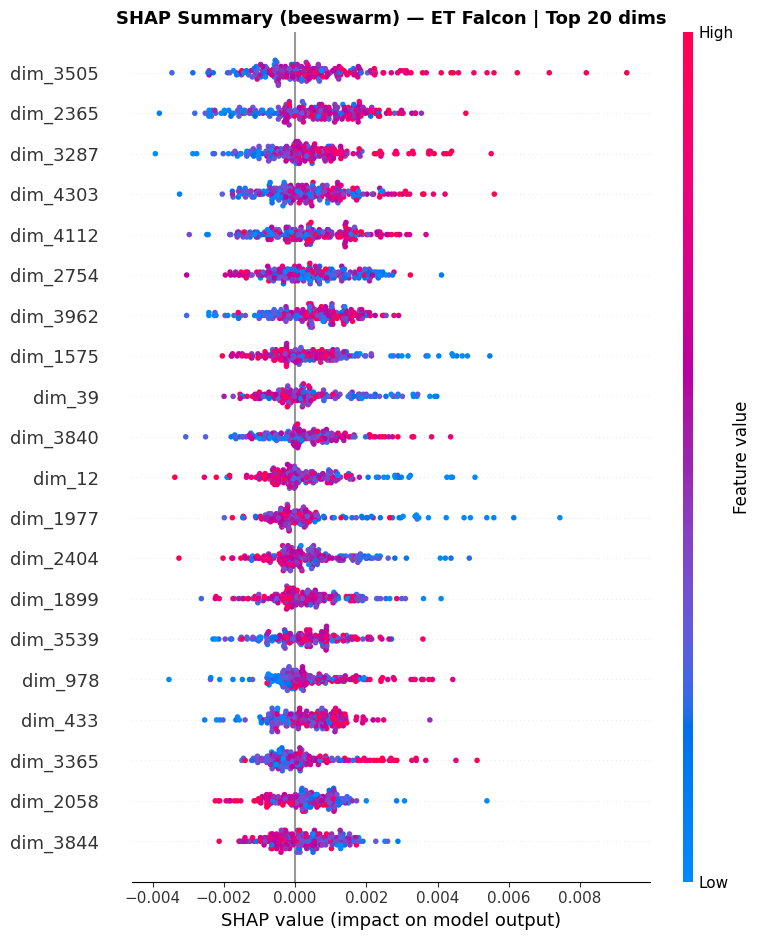

✅ shap_summary_falcon.png


/tmp/ipykernel_50/3709236295.py:87: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


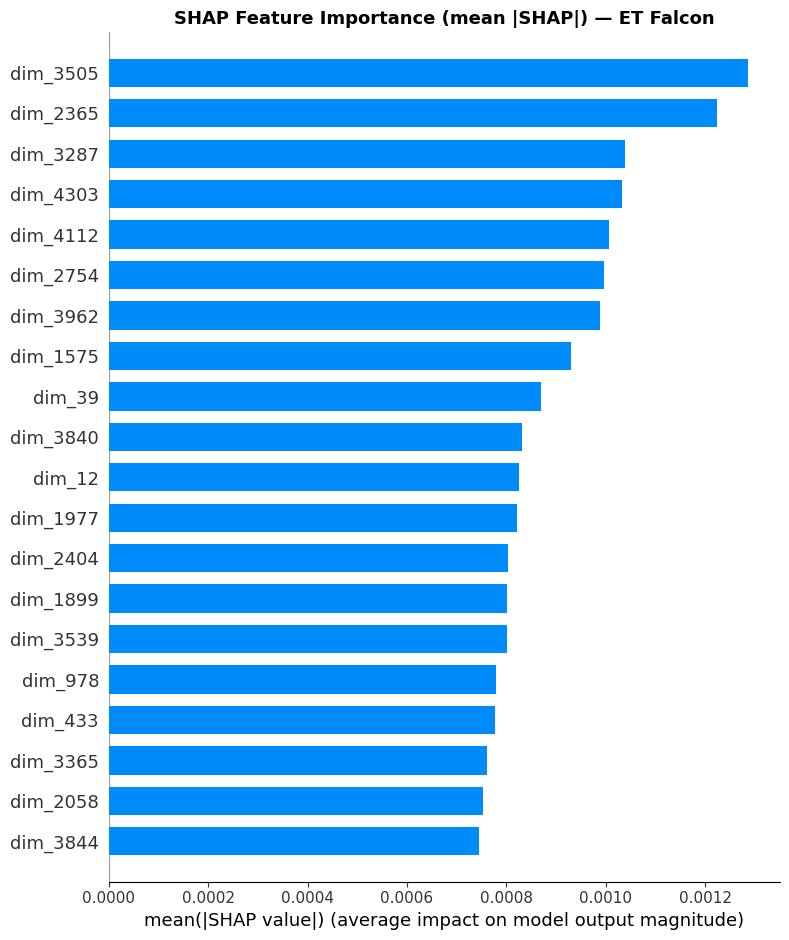

✅ shap_bar_falcon.png


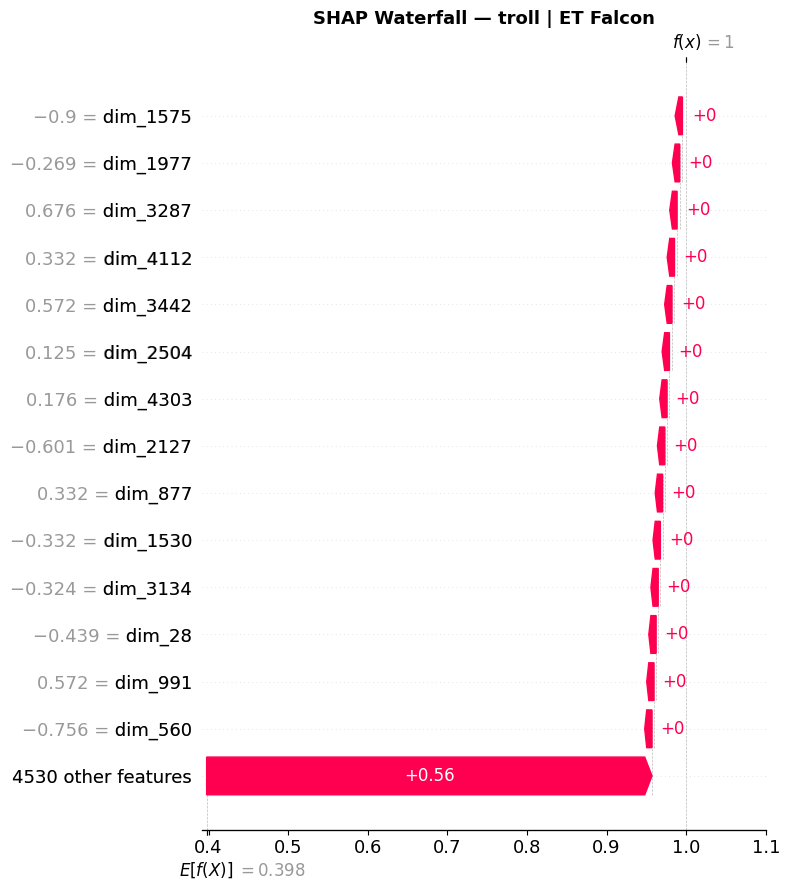

✅ /kaggle/working/shap_waterfall_troll.png


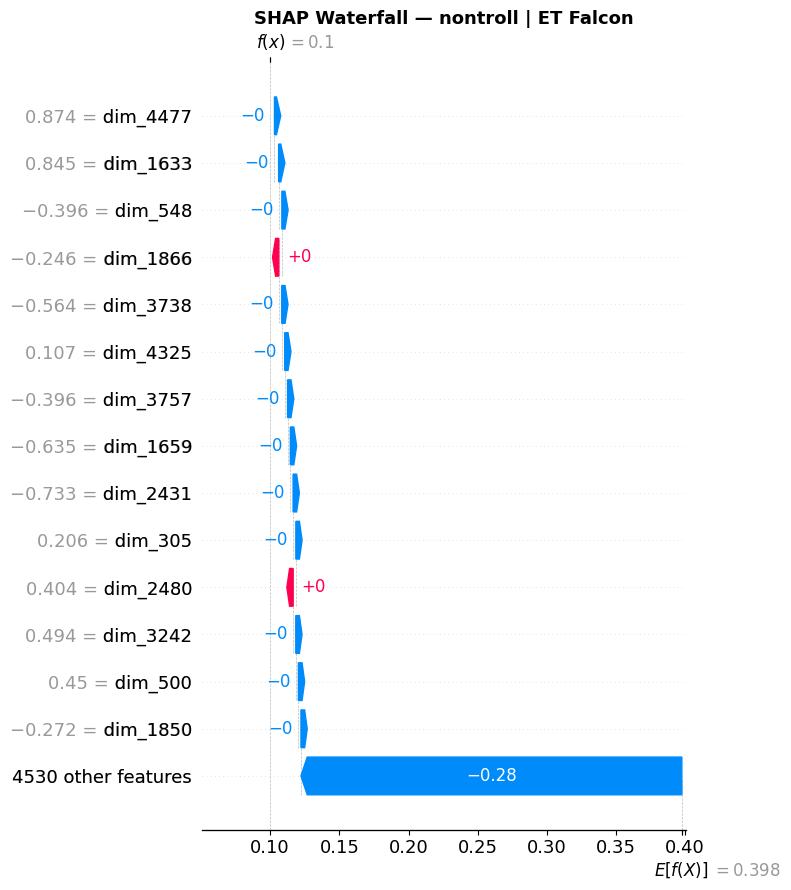

✅ /kaggle/working/shap_waterfall_nontroll.png


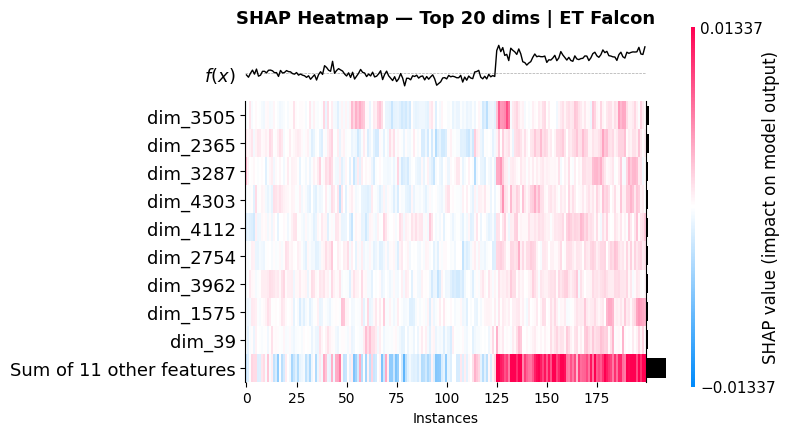

✅ shap_heatmap_falcon.png

  LIME ANALYSIS — ET-Falcon

Generating LIME: Troll (idx 0)...


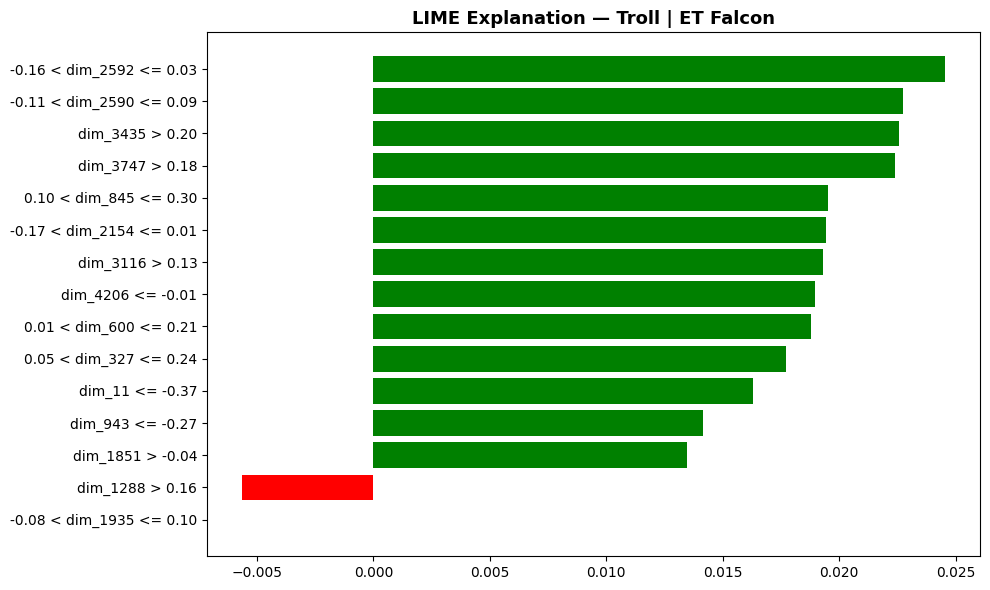

✅ /kaggle/working/lime_troll.png
✅ /kaggle/working/lime_troll.html

Top 10 LIME features (Troll):
  -0.16 < dim_2592 <= 0.03            +0.024538  → TROLL
  -0.11 < dim_2590 <= 0.09            +0.022747  → TROLL
  dim_3435 > 0.20                     +0.022578  → TROLL
  dim_3747 > 0.18                     +0.022412  → TROLL
  0.10 < dim_845 <= 0.30              +0.019518  → TROLL
  -0.17 < dim_2154 <= 0.01            +0.019422  → TROLL
  dim_3116 > 0.13                     +0.019310  → TROLL
  dim_4206 <= -0.01                   +0.018971  → TROLL
  0.01 < dim_600 <= 0.21              +0.018786  → TROLL
  0.05 < dim_327 <= 0.24              +0.017714  → TROLL

Generating LIME: Non_Troll (idx 2)...


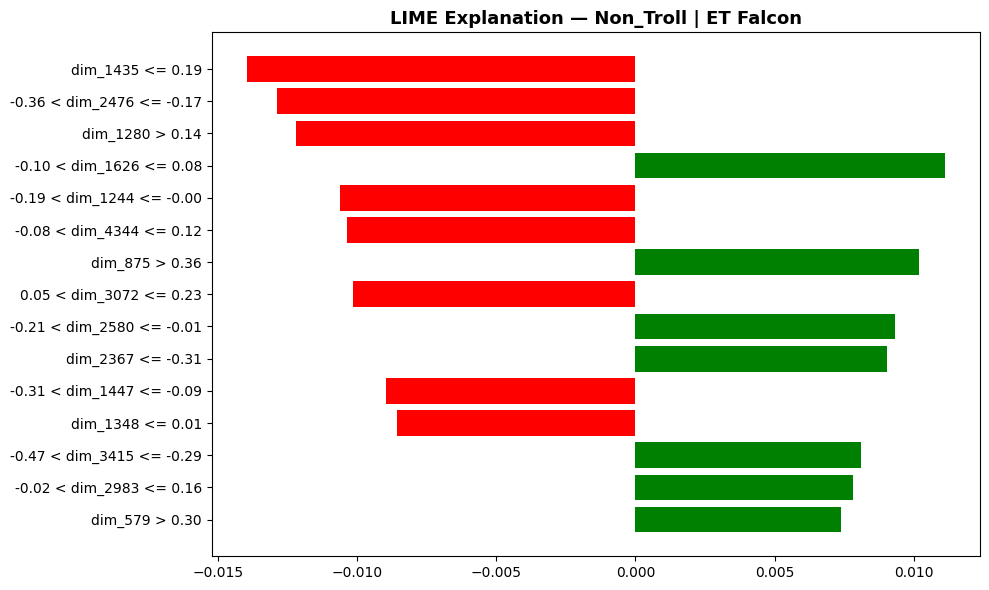

✅ /kaggle/working/lime_non_troll.png
✅ /kaggle/working/lime_non_troll.html

Top 10 LIME features (Non_Troll):
  dim_1435 <= 0.19                    -0.013961  → NON-TROLL
  -0.36 < dim_2476 <= -0.17           -0.012856  → NON-TROLL
  dim_1280 > 0.14                     -0.012198  → NON-TROLL
  -0.10 < dim_1626 <= 0.08            +0.011124  → TROLL
  -0.19 < dim_1244 <= -0.00           -0.010600  → NON-TROLL
  -0.08 < dim_4344 <= 0.12            -0.010343  → NON-TROLL
  dim_875 > 0.36                      +0.010188  → TROLL
  0.05 < dim_3072 <= 0.23             -0.010147  → NON-TROLL
  -0.21 < dim_2580 <= -0.01           +0.009311  → TROLL
  dim_2367 <= -0.31                   +0.009051  → TROLL

✅ All SHAP + LIME files saved.
   shap_summary_falcon.png
   shap_bar_falcon.png
   shap_waterfall_troll.png
   shap_waterfall_nontroll.png
   shap_heatmap_falcon.png
   lime_troll.png / .html
   lime_non_troll.png / .html


In [47]:
import shap
import lime
import lime.lime_tabular
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ================================================================
# NUMPY FIX
# ================================================================
y_test_arr  = y_test.values  if isinstance(y_test,  pd.Series) else np.array(y_test)
y_train_arr = y_train.values if isinstance(y_train, pd.Series) else np.array(y_train)

# ================================================================
# SHAP — ET-Falcon
# ================================================================
print("="*55)
print("  SHAP ANALYSIS — ET-Falcon")
print("="*55)

np.random.seed(42)
sample_idx    = np.random.choice(len(X_test_falcon), 200, replace=False)
X_shap_sample = X_test_falcon[sample_idx]
y_shap_sample = y_test_arr[sample_idx]

print(f"Sample shape : {X_shap_sample.shape}")
print(f"Class dist   : {np.bincount(y_shap_sample)}")

explainer_shap = shap.TreeExplainer(et_falcon)

print("Computing SHAP values...")
shap_values = explainer_shap.shap_values(X_shap_sample)
expected    = explainer_shap.expected_value

print(f"shap_values type  : {type(shap_values)}")
print(f"shap_values shape : {np.array(shap_values).shape}")
print(f"expected_value    : {expected}")

# ================================================================
# HANDLE ALL SHAP OUTPUT FORMATS
# ── Format A: list of 2 arrays  → old shap  [class0, class1]
# ── Format B: 3D array (n,f,2)  → new shap  axis-2 = classes
# ── Format C: 2D array (n,f)    → single output model
# ================================================================
shap_values = np.array(shap_values)

if shap_values.ndim == 3:
    # NEW shap: shape (n_samples, n_features, n_classes)
    sv       = shap_values[:, :, 1]          # class 1 = Troll
    base_val = float(expected[1]) if hasattr(expected, '__len__') else float(expected)
    print("Format: 3D array → using [:,:,1] for Troll class")

elif shap_values.ndim == 2:
    # Single output: shape (n_samples, n_features)
    sv       = shap_values
    base_val = float(expected[0]) if hasattr(expected, '__len__') else float(expected)
    print("Format: 2D array → single output")

else:
    # list of arrays: shape (2, n_samples, n_features)
    sv       = shap_values[1]                # class 1 = Troll
    base_val = float(expected[1]) if hasattr(expected, '__len__') else float(expected)
    print("Format: list/stacked → using [1] for Troll class")

print(f"sv shape   : {sv.shape}")
print(f"base_value : {base_val:.4f}")

feat_names = [f"dim_{i}" for i in range(X_test_falcon.shape[1])]

# ── Plot 1: Summary beeswarm ─────────────────────────────────────
plt.figure(figsize=(10, 6))
shap.summary_plot(
    sv, X_shap_sample,
    feature_names=feat_names,
    max_display=20, show=False, plot_type="dot"
)
plt.title("SHAP Summary (beeswarm) — ET Falcon | Top 20 dims",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("/kaggle/working/shap_summary_falcon.png",
            dpi=1200, bbox_inches='tight', facecolor='white')
plt.show(); plt.close()
print("✅ shap_summary_falcon.png")

# ── Plot 2: Bar (mean |SHAP|) ────────────────────────────────────
plt.figure(figsize=(10, 6))
shap.summary_plot(
    sv, X_shap_sample,
    feature_names=feat_names,
    max_display=20, show=False, plot_type="bar"
)
plt.title("SHAP Feature Importance (mean |SHAP|) — ET Falcon",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("/kaggle/working/shap_bar_falcon.png",
            dpi=1200, bbox_inches='tight', facecolor='white')
plt.show(); plt.close()
print("✅ shap_bar_falcon.png")

# ── Plot 3: Waterfall for troll + non-troll ──────────────────────
troll_idx    = np.where(y_shap_sample == 1)[0][0]
nontroll_idx = np.where(y_shap_sample == 0)[0][0]

for label, idx in [("troll", troll_idx), ("nontroll", nontroll_idx)]:
    exp = shap.Explanation(
        values        = sv[idx],
        base_values   = base_val,
        data          = X_shap_sample[idx],
        feature_names = feat_names
    )
    plt.figure(figsize=(10, 5))
    shap.waterfall_plot(exp, max_display=15, show=False)
    plt.title(f"SHAP Waterfall — {label} | ET Falcon",
              fontsize=13, fontweight='bold')
    plt.tight_layout()
    path = f"/kaggle/working/shap_waterfall_{label}.png"
    plt.savefig(path, dpi=1200, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()
    print(f"✅ {path}")

# ── Plot 4: Heatmap (top 20 features across all samples) ─────────
top20_idx = np.argsort(np.abs(sv).mean(axis=0))[-20:]
plt.figure(figsize=(12, 6))
shap.plots.heatmap(
    shap.Explanation(
        values        = sv[:, top20_idx],
        base_values   = np.full(len(sv), base_val),
        data          = X_shap_sample[:, top20_idx],
        feature_names = [feat_names[i] for i in top20_idx]
    ),
    show=False
)
plt.title("SHAP Heatmap — Top 20 dims | ET Falcon",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("/kaggle/working/shap_heatmap_falcon.png",
            dpi=1200, bbox_inches='tight', facecolor='white')
plt.show(); plt.close()
print("✅ shap_heatmap_falcon.png")

# ================================================================
# LIME — ET-Falcon
# ================================================================
print("\n" + "="*55)
print("  LIME ANALYSIS — ET-Falcon")
print("="*55)

explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data         = X_train_falcon.astype(np.float32),
    feature_names         = feat_names,
    class_names           = ["Non-Troll", "Troll"],
    mode                  = "classification",
    discretize_continuous = True,
    random_state          = 42
)

test_troll_idx    = np.where(y_test_arr == 1)[0][0]
test_nontroll_idx = np.where(y_test_arr == 0)[0][0]

for label, idx in [("Troll",     test_troll_idx),
                   ("Non_Troll", test_nontroll_idx)]:
    print(f"\nGenerating LIME: {label} (idx {idx})...")

    exp_lime = explainer_lime.explain_instance(
        data_row     = X_test_falcon[idx].astype(np.float32),
        predict_fn   = et_falcon.predict_proba,
        num_features = 15,
        num_samples  = 500,
        labels       = (1,)
    )

    fig = exp_lime.as_pyplot_figure(label=1)
    fig.set_size_inches(10, 6)
    plt.title(f"LIME Explanation — {label} | ET Falcon",
              fontsize=13, fontweight='bold')
    plt.tight_layout()
    path = f"/kaggle/working/lime_{label.lower()}.png"
    plt.savefig(path, dpi=600, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()
    print(f"✅ {path}")

    exp_lime.save_to_file(path.replace(".png", ".html"))
    print(f"✅ {path.replace('.png', '.html')}")

    print(f"\nTop 10 LIME features ({label}):")
    for feat, weight in exp_lime.as_list(label=1)[:10]:
        direction = "→ TROLL" if weight > 0 else "→ NON-TROLL"
        print(f"  {feat:<35} {weight:+.6f}  {direction}")

print("\n✅ All SHAP + LIME files saved.")
print("   shap_summary_falcon.png")
print("   shap_bar_falcon.png")
print("   shap_waterfall_troll.png")
print("   shap_waterfall_nontroll.png")
print("   shap_heatmap_falcon.png")
print("   lime_troll.png / .html")
print("   lime_non_troll.png / .html")

In [49]:

# Generate predictions using trained classifiers

y_pred_et = et_falcon.predict(X_test_falcon)
y_pred_rf = rf_falcon.predict(X_test_falcon)
y_pred_xgb = xb_falcon.predict(X_test_falcon)

print("ET predictions:", len(y_pred_et))
print("RF predictions:", len(y_pred_rf))
print("XGB predictions:", len(y_pred_xgb))


ET predictions: 3967
RF predictions: 3967
XGB predictions: 3967


# McNemar's test

In [50]:

import numpy as np
import pandas as pd

from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

# Use predictions from your FINAL Falcon-7B models.
# Replace these variable names with your actual ones.

predictions = {
    "ET": np.asarray(y_pred_et),
    "RF": np.asarray(y_pred_rf),
    "XGB": np.asarray(y_pred_xgb)
}

y_true = np.asarray(y_test)

comparisons = [
    ("ET", "RF"),
    ("ET", "XGB"),
    ("RF", "XGB")
]

results = []

for model_a, model_b in comparisons:

    a_correct = predictions[model_a] == y_true
    b_correct = predictions[model_b] == y_true

    # Discordant correctness counts
    a_only = np.sum(a_correct & ~b_correct)
    b_only = np.sum(~a_correct & b_correct)

    # Paired correctness contingency table
    table = [
        [np.sum(a_correct & b_correct), a_only],
        [b_only, np.sum(~a_correct & ~b_correct)]
    ]

    test = mcnemar(table, exact=True)

    results.append({
        "Comparison": f"{model_a} vs. {model_b}",
        "A-only correct": int(a_only),
        "B-only correct": int(b_only),
        "p-value": test.pvalue
    })

df = pd.DataFrame(results)

# Holm correction for three pairwise comparisons
df["Adjusted p"] = multipletests(
    df["p-value"],
    method="holm"
)[1]

df["Significant"] = df["Adjusted p"] < 0.05

print(df.to_string(index=False))


Comparison  A-only correct  B-only correct      p-value   Adjusted p  Significant
 ET vs. RF              31               6 4.125759e-05 4.125759e-05         True
ET vs. XGB              96              19 1.446748e-13 4.340243e-13         True
RF vs. XGB              71              19 3.127182e-08 6.254365e-08         True


In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# All nine trained models
models = {
    "TF-IDF + RF":  (rf_tfidf, X_tfidf_test),
    "TF-IDF + XGB": (xb_tfidf, X_tfidf_test),
    "TF-IDF + ET":  (et_tfidf, X_tfidf_test),

    "Word2Vec + RF":  (rf_w2v, X_w2v_test),
    "Word2Vec + XGB": (xb_w2v, X_w2v_test),
    "Word2Vec + ET":  (et_w2v, X_w2v_test),

    "Falcon-7B + RF":  (rf_falcon, X_test_falcon),
    "Falcon-7B + XGB": (xb_falcon, X_test_falcon),
    "Falcon-7B + ET":  (et_falcon, X_test_falcon)
}

print("Total models:", len(models))


Total models: 9


# ROC

In [52]:

print("=" * 55)
print("GENERATING ROC AND PR DATA")
print("=" * 55)

curve_results = {}
metric_results = []

y_true = np.asarray(y_test).astype(int)

for name, (model, X_test_model) in models.items():

    # Check test-set alignment
    if X_test_model.shape[0] != len(y_true):
        raise ValueError(
            f"{name}: Test sample count does not match y_test."
        )

    # Get positive-class probability
    class_idx = list(model.classes_).index(1)

    y_score = model.predict_proba(
        X_test_model
    )[:, class_idx]

    # ROC curve
    fpr, tpr, _ = roc_curve(
        y_true, y_score
    )

    roc_auc = roc_auc_score(
        y_true, y_score
    )

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(
        y_true, y_score
    )

    ap = average_precision_score(
        y_true, y_score
    )

    # Save all curve information
    curve_results[name] = {
        "fpr": fpr,
        "tpr": tpr,
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "ap": ap
    }

    metric_results.append({
        "Model": name,
        "ROC_AUC": roc_auc,
        "AP": ap
    })

    print(
        f"{name}: ROC-AUC = {roc_auc:.4f}, "
        f"AP = {ap:.4f}"
    )

# Results table
metrics_df = pd.DataFrame(metric_results)

print("\nFinal ROC and PR summary:")
print(metrics_df.round(4).to_string(index=False))


GENERATING ROC AND PR DATA
TF-IDF + RF: ROC-AUC = 0.9783, AP = 0.9654
TF-IDF + XGB: ROC-AUC = 0.9473, AP = 0.9052
TF-IDF + ET: ROC-AUC = 0.9831, AP = 0.9785
Word2Vec + RF: ROC-AUC = 0.9781, AP = 0.9704
Word2Vec + XGB: ROC-AUC = 0.9726, AP = 0.9542
Word2Vec + ET: ROC-AUC = 0.9809, AP = 0.9803
Falcon-7B + RF: ROC-AUC = 0.9855, AP = 0.9865
Falcon-7B + XGB: ROC-AUC = 0.9841, AP = 0.9853
Falcon-7B + ET: ROC-AUC = 0.9839, AP = 0.9848

Final ROC and PR summary:
          Model  ROC_AUC     AP
    TF-IDF + RF   0.9783 0.9654
   TF-IDF + XGB   0.9473 0.9052
    TF-IDF + ET   0.9831 0.9785
  Word2Vec + RF   0.9781 0.9704
 Word2Vec + XGB   0.9726 0.9542
  Word2Vec + ET   0.9809 0.9803
 Falcon-7B + RF   0.9855 0.9865
Falcon-7B + XGB   0.9841 0.9853
 Falcon-7B + ET   0.9839 0.9848


FIGURE 3(a): COMBINED ROC CURVE


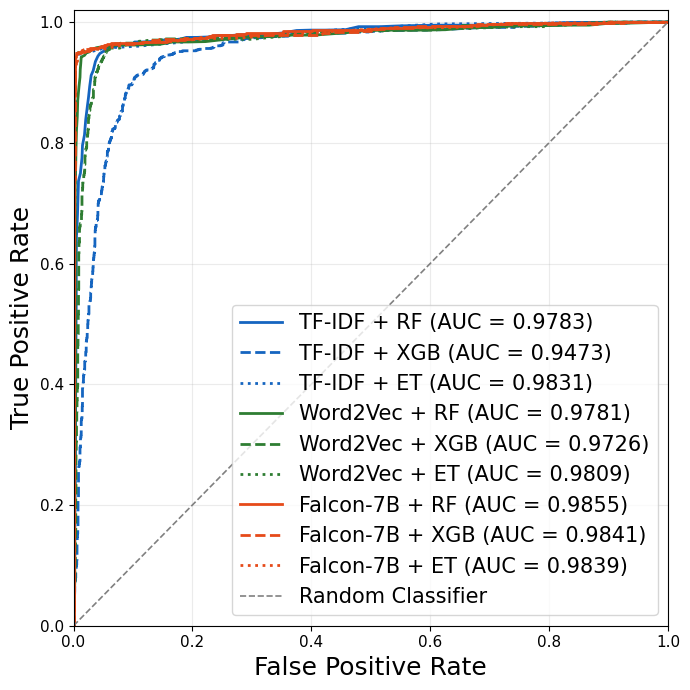

In [53]:

print("=" * 55)
print("FIGURE 3(a): COMBINED ROC CURVE")
print("=" * 55)

# Feature extractor colors
colors = {
    "TF-IDF": "#1565C0",
    "Word2Vec": "#2E7D32",
    "Falcon-7B": "#E64A19"
}

# Classifier line styles
styles = {
    "RF": "-",
    "XGB": "--",
    "ET": ":"
}

fig, ax = plt.subplots(figsize=(7, 7))

for name, result in curve_results.items():

    extractor, classifier = name.split(" + ")

    ax.plot(
        result["fpr"],
        result["tpr"],
        color=colors[extractor],
        linestyle=styles[classifier],
        linewidth=2,
        label=f'{name} (AUC = {result["roc_auc"]:.4f})'
    )

# Random-classifier baseline
ax.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Random Classifier"
)

ax.set_xlabel("False Positive Rate", fontsize=18)
ax.set_ylabel("True Positive Rate", fontsize=18)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.tick_params(labelsize=11)
ax.grid(alpha=0.25)

# Legend placed outside the curve area
ax.legend(
    loc="lower right",
    fontsize=15,
    frameon=True
)

plt.tight_layout()

# Save genuine high-resolution figure
fig.savefig(
    "Figure3a_ROC_600dpi.png",
    dpi=1200,
    bbox_inches="tight"
)

# Vector PDF
fig.savefig(
    "Figure3a_ROC.pdf",
    bbox_inches="tight"
)

plt.show()


# PR

FIGURE 3(b): COMBINED PR CURVE


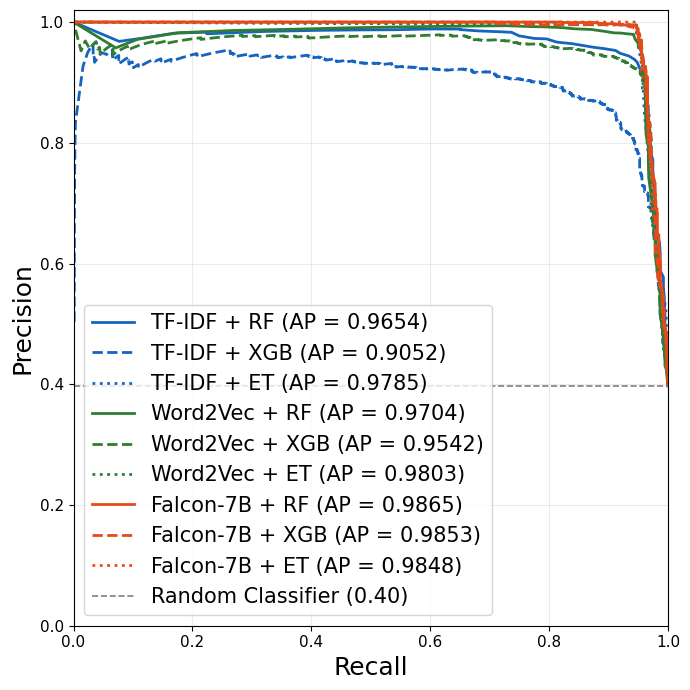

PR baseline: 0.3975


In [54]:

print("=" * 55)
print("FIGURE 3(b): COMBINED PR CURVE")
print("=" * 55)

fig, ax = plt.subplots(figsize=(7, 7))

for name, result in curve_results.items():

    extractor, classifier = name.split(" + ")

    ax.plot(
        result["recall"],
        result["precision"],
        color=colors[extractor],
        linestyle=styles[classifier],
        linewidth=2,
        label=f'{name} (AP = {result["ap"]:.4f})'
    )

# Random-classifier baseline
baseline = np.mean(y_true == 1)

ax.axhline(
    y=baseline,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label=f"Random Classifier ({baseline:.2f})"
)

ax.set_xlabel("Recall", fontsize=18)
ax.set_ylabel("Precision", fontsize=18)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.tick_params(labelsize=11)
ax.grid(alpha=0.25)

ax.legend(
    loc="lower left",
    fontsize=15,
    frameon=True
)

plt.tight_layout()

# Save 600 DPI PNG
fig.savefig(
    "Figure3b_PR_600dpi.png",
    dpi=1200,
    bbox_inches="tight"
)

# Save vector PDF
fig.savefig(
    "Figure3b_PR.pdf",
    bbox_inches="tight"
)

plt.show()

print("PR baseline:", round(baseline, 4))


# 10 Fold CV

In [55]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from xgboost import XGBClassifier

# Falcon embeddings and training labels
X_cv = np.asarray(X_train_falcon)
y_cv = np.asarray(y_train).astype(int)

assert X_cv.shape[0] == len(y_cv)
assert set(np.unique(y_cv)) == {0, 1}

# Standard stratified 10-fold cross-validation
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(X_cv, y_cv))

print("Training samples:", len(y_cv))
print("Total folds:", len(folds))
print("Falcon embedding shape:", X_cv.shape)


Training samples: 15867
Total folds: 10
Falcon embedding shape: (15867, 4544)


In [56]:

models_falcon = {

    "Falcon-7B + RF": RandomForestClassifier(
n_estimators      = 200, # 200
max_features      = 'sqrt',
min_samples_split = 2, #i
min_samples_leaf  = 2, #2
class_weight      = 'balanced',
random_state      = 42,
n_jobs            = -1
),

    "Falcon-7B + XGB": XGBClassifier(
colsample_bytree=0.8, # 0.3
gamma=0.2,  # f -> 0.2
learning_rate=0.1,  # 0.1 
max_depth=65,  # 65   i
min_child_weight=1,
n_estimators=150, #I  150
reg_alpha=0,
reg_lambda=1, # 1
subsample=0.8,  #0.81
random_state=42
),

    "Falcon-7B + ET": ExtraTreesClassifier(bootstrap= False, 
      criterion='gini', 
      max_depth= None, 
      max_features= 'log2', 
      min_samples_leaf= 1, 
      min_samples_split=2,  #i  2
      n_estimators=100,#i 138
      random_state=42)
    
}

print("Models configured successfully.")


Models configured successfully.


In [57]:

fold_results = []
summary_results = []

for model_name, model in models_falcon.items():

    print("\n" + "=" * 65)
    print("10-FOLD CV:", model_name)
    print("=" * 65)

    acc_scores = []
    f1_scores = []

    for fold_no, (tr_idx, val_idx) in enumerate(
        folds, start=1
    ):

        # Create a fresh model for every fold
        clf = clone(model)

        # Train on 9 folds
        clf.fit(
            X_cv[tr_idx],
            y_cv[tr_idx]
        )

        # Predict on remaining fold
        y_pred = clf.predict(X_cv[val_idx])

        # Calculate metrics
        acc = accuracy_score(
            y_cv[val_idx], y_pred
        ) * 100

        f1 = f1_score(
            y_cv[val_idx],
            y_pred,
            pos_label=1,
            zero_division=0
        ) * 100

        acc_scores.append(acc)
        f1_scores.append(f1)

        fold_results.append({
            "Model": model_name,
            "Fold": fold_no,
            "Accuracy (%)": acc,
            "F1 (%)": f1
        })

        print(
            f"Fold {fold_no:02d} | "
            f"Accuracy: {acc:.2f}% | "
            f"F1: {f1:.2f}%"
        )

    summary_results.append({
        "Model": model_name,
        "Accuracy Mean (%)": np.mean(acc_scores),
        "Accuracy SD (%)": np.std(acc_scores, ddof=1),
        "F1 Mean (%)": np.mean(f1_scores),
        "F1 SD (%)": np.std(f1_scores, ddof=1)
    })

    print("-" * 65)
    print(
        f"Average Accuracy: "
        f"{np.mean(acc_scores):.2f}% "
        f"± {np.std(acc_scores, ddof=1):.2f}%"
    )
    print(
        f"Average F1: "
        f"{np.mean(f1_scores):.2f}% "
        f"± {np.std(f1_scores, ddof=1):.2f}%"
    )



10-FOLD CV: Falcon-7B + RF
Fold 01 | Accuracy: 95.15% | F1: 93.65%
Fold 02 | Accuracy: 94.14% | F1: 92.28%
Fold 03 | Accuracy: 95.53% | F1: 94.16%
Fold 04 | Accuracy: 94.64% | F1: 92.96%
Fold 05 | Accuracy: 95.27% | F1: 93.83%
Fold 06 | Accuracy: 94.64% | F1: 93.03%
Fold 07 | Accuracy: 94.90% | F1: 93.27%
Fold 08 | Accuracy: 95.40% | F1: 94.01%
Fold 09 | Accuracy: 93.95% | F1: 92.05%
Fold 10 | Accuracy: 95.21% | F1: 93.76%
-----------------------------------------------------------------
Average Accuracy: 94.88% ± 0.53%
Average F1: 93.30% ± 0.72%

10-FOLD CV: Falcon-7B + XGB
Fold 01 | Accuracy: 94.77% | F1: 93.25%
Fold 02 | Accuracy: 93.64% | F1: 91.73%
Fold 03 | Accuracy: 95.27% | F1: 93.92%
Fold 04 | Accuracy: 94.20% | F1: 92.50%
Fold 05 | Accuracy: 94.58% | F1: 93.03%
Fold 06 | Accuracy: 94.01% | F1: 92.34%
Fold 07 | Accuracy: 94.39% | F1: 92.77%
Fold 08 | Accuracy: 94.77% | F1: 93.34%
Fold 09 | Accuracy: 93.57% | F1: 91.69%
Fold 10 | Accuracy: 94.70% | F1: 93.23%
-----------------